# Surrogate-Assisted GA + PSO for FSDT/CLT 16-Ply Laminate Frequency Optimisation

Back to a **single material** (no material-selection gene), now optimising a
**16-ply** symmetric laminate (8 independent half-layup angles, twice the original
4). Two surrogate-assisted searches are compared against a matched-budget direct GA:

- **SA-GA** -- the same surrogate-assisted genetic algorithm as before.
- **SA-PSO** -- the same surrogate, but the cheap inner-loop optimiser is now a
  particle swarm instead of a GA (mirroring the three-way comparison in the main
  notebook: Direct GA / SA-GA / SA-PSO, all under an equal TRUE-FEM budget).

Everything else keeps the "no speed tricks" spirit: the reference FEM is still
rebuilt element-by-element from scratch on every TRUE evaluation, the eigensolver
is still dense `la.eigh` on the full spectrum, and the only new ingredient is the
CLT-based surrogate sitting inside the optimiser loop.

## 1. Material properties and problem setup

In [ ]:
import time
import numpy as np
import scipy.linalg as la
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Material properties (T300/5208-type carbon/epoxy)
E1, E2, G12, nu12, rho = 181e9, 10.3e9, 7.17e9, 0.28, 1600.0
G13 = G12
G23 = G12

Ks = 5.0 / 6.0

ply_thickness = 0.25e-3       # m, fixed for every candidate design
n_half = 8                    # 8 independent angles -> 16-ply symmetric laminate
a_plate, b_plate = 1.0, 1.0   # m
nx, ny = 10, 10                # mesh (modest, since every eval redoes the full assembly)
boundary_code = 'SSSS'        # simply supported on all 4 edges

print(f"Setup ready: {2*n_half}-ply symmetric laminate, {n_half} independent angles.")

Setup ready: 16-ply symmetric laminate, 8 independent angles.


## 2. Classical Lamination Theory (ply-by-ply loop, no vectorisation)

In [ ]:
def reduced_stiffness(E1, E2, nu12, G12):
    nu21 = nu12 * E2 / E1
    denom = 1 - nu12 * nu21
    return E1 / denom, nu12 * E2 / denom, E2 / denom, G12


def transform_Qbar(Q11, Q12, Q22, Q66, theta_rad):
    m, n = np.cos(theta_rad), np.sin(theta_rad)
    Q11b = Q11*m**4 + 2*(Q12 + 2*Q66)*m**2*n**2 + Q22*n**4
    Q12b = (Q11 + Q22 - 4*Q66)*m**2*n**2 + Q12*(m**4 + n**4)
    Q22b = Q11*n**4 + 2*(Q12 + 2*Q66)*m**2*n**2 + Q22*m**4
    Q16b = (Q11 - Q12 - 2*Q66)*m**3*n - (Q22 - Q12 - 2*Q66)*m*n**3
    Q26b = (Q11 - Q12 - 2*Q66)*m*n**3 - (Q22 - Q12 - 2*Q66)*m**3*n
    Q66b = (Q11 + Q22 - 2*Q12 - 2*Q66)*m**2*n**2 + Q66*(m**4 + n**4)
    return np.array([[Q11b, Q12b, Q16b],
                      [Q12b, Q22b, Q26b],
                      [Q16b, Q26b, Q66b]])


def transform_shear(G13, G23, theta_rad):
    m, n = np.cos(theta_rad), np.sin(theta_rad)
    Q44b = G23*m**2 + G13*n**2
    Q55b = G13*m**2 + G23*n**2
    Q45b = (G13 - G23)*m*n
    return np.array([[Q55b, Q45b],
                      [Q45b, Q44b]])


def compute_laminate_properties(layup_angles_deg, ply_thickness,
                                 E1, E2, nu12, G12, G13, G23, rho, Ks):
    n_plies = len(layup_angles_deg)
    t_tot = n_plies * ply_thickness
    z = np.linspace(-t_tot/2, t_tot/2, n_plies + 1)

    Q11, Q12, Q22, Q66 = reduced_stiffness(E1, E2, nu12, G12)
    Db = np.zeros((3, 3)); Ds = np.zeros((2, 2)); C0 = 0.0; C1 = 0.0

    for k, theta_deg in enumerate(layup_angles_deg):
        th = np.radians(theta_deg)
        z_bot, z_top = z[k], z[k+1]
        Db += transform_Qbar(Q11, Q12, Q22, Q66, th) * (z_top**3 - z_bot**3) / 3.0
        Ds += Ks * transform_shear(G13, G23, th) * (z_top - z_bot)
        C0 += rho * (z_top - z_bot)
        C1 += rho * (z_top**3 - z_bot**3) / 3.0

    return Db, Ds, C0, C1, t_tot

print("CLT ready.")

CLT ready.


## 3. Reference FEM: 4-node FSDT/Mindlin plate, full element-by-element assembly

In [ ]:
def build_mesh(a, b, nx, ny):
    nnx, nny = nx + 1, ny + 1
    nodes = np.zeros((nnx*nny, 2))
    idx = 0
    for j in range(nny):
        for i in range(nnx):
            nodes[idx] = [i*(a/nx), j*(b/ny)]
            idx += 1
    elements = []
    for j in range(ny):
        for i in range(nx):
            n1 = j*nnx + i
            elements.append([n1, n1 + 1, n1 + 1 + nnx, n1 + nnx])
    return nodes, np.array(elements)


def shape_functions(xi, eta):
    N = 0.25*np.array([(1-xi)*(1-eta), (1+xi)*(1-eta),
                        (1+xi)*(1+eta), (1-xi)*(1+eta)])
    dN_dxi  = 0.25*np.array([-(1-eta), (1-eta), (1+eta), -(1+eta)])
    dN_deta = 0.25*np.array([-(1-xi), -(1+xi), (1+xi), (1-xi)])
    return N, dN_dxi, dN_deta


def assemble_global_matrices(nodes, elements, Db, Ds, C0, C1):
    gauss_full = np.array([-1/np.sqrt(3), 1/np.sqrt(3)])
    gauss_red  = np.array([0.0])

    total_dofs   = len(nodes)*3
    K_global     = np.zeros((total_dofs, total_dofs))
    M_global     = np.zeros((total_dofs, total_dofs))
    Mass_density = np.diag([C0, C1, C1])

    for el in elements:
        coords = nodes[el]
        Ke = np.zeros((12, 12)); Me = np.zeros((12, 12))

        for xi in gauss_full:
            for eta in gauss_full:
                N, dN_dxi, dN_deta = shape_functions(xi, eta)
                J = np.array([[dN_dxi  @ coords[:, 0], dN_dxi  @ coords[:, 1]],
                              [dN_deta @ coords[:, 0], dN_deta @ coords[:, 1]]])
                detJ = np.linalg.det(J); invJ = np.linalg.inv(J)
                dN_dx = invJ[0, 0]*dN_dxi + invJ[0, 1]*dN_deta
                dN_dy = invJ[1, 0]*dN_dxi + invJ[1, 1]*dN_deta

                Bb = np.zeros((3, 12))
                for i in range(4):
                    Bb[0, i*3+1] = dN_dx[i]
                    Bb[1, i*3+2] = dN_dy[i]
                    Bb[2, i*3+1] = dN_dy[i]; Bb[2, i*3+2] = dN_dx[i]

                N_mat = np.zeros((3, 12))
                for i in range(4):
                    N_mat[0, i*3]   = N[i]
                    N_mat[1, i*3+1] = N[i]
                    N_mat[2, i*3+2] = N[i]

                Ke += Bb.T @ Db @ Bb * detJ
                Me += N_mat.T @ Mass_density @ N_mat * detJ

        for xi in gauss_red:
            for eta in gauss_red:
                N, dN_dxi, dN_deta = shape_functions(xi, eta)
                J = np.array([[dN_dxi  @ coords[:, 0], dN_dxi  @ coords[:, 1]],
                              [dN_deta @ coords[:, 0], dN_deta @ coords[:, 1]]])
                detJ = np.linalg.det(J); invJ = np.linalg.inv(J)
                dN_dx = invJ[0, 0]*dN_dxi + invJ[0, 1]*dN_deta
                dN_dy = invJ[1, 0]*dN_dxi + invJ[1, 1]*dN_deta

                Bs = np.zeros((2, 12))
                for i in range(4):
                    Bs[0, i*3] = dN_dx[i]; Bs[0, i*3+1] = N[i]
                    Bs[1, i*3] = dN_dy[i]; Bs[1, i*3+2] = N[i]

                Ke += Bs.T @ Ds @ Bs * detJ * 4.0

        for i in range(4):
            for j in range(4):
                for p in range(3):
                    for q in range(3):
                        K_global[el[i]*3+p, el[j]*3+q] += Ke[i*3+p, j*3+q]
                        M_global[el[i]*3+p, el[j]*3+q] += Me[i*3+p, j*3+q]

    return K_global, M_global


def get_fixed_dofs(nodes, a, b, boundary_code):
    c = dict(left=boundary_code[0].upper(),   right=boundary_code[1].upper(),
             bottom=boundary_code[2].upper(), top=boundary_code[3].upper())
    fixed = set()
    for i, (x, y) in enumerate(nodes):
        w, tx, ty = i*3, i*3+1, i*3+2
        if np.isclose(x, 0.0):
            if   c['left'] == 'C': fixed.update([w, tx, ty])
            elif c['left'] == 'S': fixed.update([w, ty])
        if np.isclose(x, a):
            if   c['right'] == 'C': fixed.update([w, tx, ty])
            elif c['right'] == 'S': fixed.update([w, ty])
        if np.isclose(y, 0.0):
            if   c['bottom'] == 'C': fixed.update([w, tx, ty])
            elif c['bottom'] == 'S': fixed.update([w, tx])
        if np.isclose(y, b):
            if   c['top'] == 'C': fixed.update([w, tx, ty])
            elif c['top'] == 'S': fixed.update([w, tx])
    return sorted(fixed)


def solve_laminate_plate_f1(layup_angles_deg, ply_thickness, a, b, nx, ny, boundary_code,
                             E1, E2, nu12, G12, G13, G23, rho, Ks=5.0/6.0):
    '''Full reference pipeline, called from scratch every time. Returns f1 [Hz] only.'''
    Db, Ds, C0, C1, t_tot = compute_laminate_properties(
        layup_angles_deg, ply_thickness, E1, E2, nu12, G12, G13, G23, rho, Ks)

    nodes, elements    = build_mesh(a, b, nx, ny)
    K_global, M_global = assemble_global_matrices(nodes, elements, Db, Ds, C0, C1)

    fixed_dofs = get_fixed_dofs(nodes, a, b, boundary_code)
    total_dofs = len(nodes)*3
    free_dofs  = np.setdiff1d(np.arange(total_dofs), fixed_dofs)

    K_c = K_global[np.ix_(free_dofs, free_dofs)]
    M_c = M_global[np.ix_(free_dofs, free_dofs)]

    eigenvalues = np.sort(la.eigh(K_c, M_c, eigvals_only=True))   # dense, FULL spectrum
    return float(np.sqrt(np.abs(eigenvalues[0])) / (2*np.pi))

print("Reference FEM ready.")

Reference FEM ready.


## 4. The TRUE objective function


In [ ]:
n_var = n_half     # 8 ply angles, one design variable per half-layup angle
lo = np.full(n_var, -90.0)
hi = np.full(n_var,  90.0)

n_eval = 0

def objective(theta_half):
    '''theta_half: array of n_half angles (deg). Mirrors it into a symmetric
    full layup and returns the resulting fundamental frequency f1 [Hz].'''
    global n_eval
    n_eval += 1
    theta_half = list(np.asarray(theta_half, dtype=float))
    full_layup = theta_half + theta_half[::-1]
    return solve_laminate_plate_f1(full_layup, ply_thickness, a_plate, b_plate, nx, ny,
                                    boundary_code, E1, E2, nu12, G12, G13, G23, rho, Ks)

print("Objective ready.")

# baseline: quasi-isotropic-ish [0/45/-45/90] pattern, repeated to fill n_half angles
baseline_half = ([0.0, 45.0, -45.0, 90.0] * ((n_half // 4) + 1))[:n_half]
f_baseline = objective(baseline_half)
print(f"Baseline half-layup {baseline_half}")
print(f"Baseline full layup {baseline_half + baseline_half[::-1]}")
print(f"Baseline f1 = {f_baseline:.4f} Hz")

Objective ready.
Baseline half-layup [0.0, 45.0, -45.0, 90.0, 0.0, 45.0, -45.0, 90.0]
Baseline full layup [0.0, 45.0, -45.0, 90.0, 0.0, 45.0, -45.0, 90.0, 90.0, -45.0, 45.0, 0.0, 90.0, -45.0, 45.0, 0.0]
Baseline f1 = 25.1337 Hz


## 5. CLT-stiffness features -- the surrogate's inputs

With a single fixed material and fixed ply thickness, the mass matrix ($C_0$, $C_1$)
is constant for every candidate design, so $f_1$ depends on the ply angles only
through the 9 independent entries of $D_b, D_s$. Handing the surrogate those 9
numbers instead of 8 raw angles is the key modelling step validated in the main
notebook's ablation (raw angles: $R^2 < 0$; CLT stiffness terms: $R^2 \approx 0.99$
from ~60 samples).

In [ ]:
def clt_features_one(theta_half):
    theta_half = list(np.asarray(theta_half, dtype=float))
    full_layup = theta_half + theta_half[::-1]
    Db, Ds, C0, C1, h = compute_laminate_properties(
        full_layup, ply_thickness, E1, E2, nu12, G12, G13, G23, rho, Ks)
    return np.array([Db[0, 0], Db[0, 1], Db[1, 1], Db[0, 2], Db[1, 2], Db[2, 2],
                      Ds[0, 0], Ds[0, 1], Ds[1, 1]])


def clt_features(X):
    '''(n, n_var) design vectors -> (n, 9) feature array. Deliberately a plain
    Python loop (no vectorised batch CLT map), consistent with this notebook's
    'no speed tricks' spirit -- it's cheap, so it doesn't need one.'''
    X = np.atleast_2d(np.asarray(X, dtype=float))
    return np.array([clt_features_one(row) for row in X])


# sanity check
_test_vec = np.array([10.0, -20.0, 33.0, 45.0, -60.0, 75.0, 88.0, -5.0])
_feat = clt_features_one(_test_vec)
assert _feat.shape == (9,) and np.all(np.isfinite(_feat))
print("CLT feature vector (D11,D12,D22,D16,D26,D66,S11,S12,S22):")
print(_feat)
print("Feature extractor OK.")

CLT feature vector (D11,D12,D22,D16,D26,D66,S11,S12,S22):
[6.38334973e+02 1.14721950e+02 1.87960576e+02 5.72311469e+01
 3.03514875e+01 1.37511686e+02 2.39000000e+07 0.00000000e+00
 2.39000000e+07]
Feature extractor OK.


## 6. A simple real-coded genetic algorithm (generic driver, MAXIMISES)

In [ ]:
def simple_ga(obj_fn, n_var, lo, hi, pop_size=20, n_gen=15,
              mutation_rate=0.2, mutation_sigma=None, rng=None,
              x_init=None, verbose=True, label="GA"):

    rng = np.random.default_rng(rng)
    lo = np.broadcast_to(np.asarray(lo, dtype=float), (n_var,)).copy()
    hi = np.broadcast_to(np.asarray(hi, dtype=float), (n_var,)).copy()
    if mutation_sigma is None:
        mutation_sigma = 0.15*(hi - lo)
    else:
        mutation_sigma = np.broadcast_to(np.asarray(mutation_sigma, dtype=float), (n_var,)).copy()

    pop = rng.uniform(lo, hi, size=(pop_size, n_var))
    if x_init is not None:
        x0 = np.atleast_2d(np.asarray(x_init, dtype=float))
        k = min(len(x0), pop_size)
        pop[:k] = x0[:k]
    fitness = np.array([obj_fn(ind) for ind in pop])

    best_idx = np.argmax(fitness)
    best_x, best_f = pop[best_idx].copy(), fitness[best_idx]
    history = [best_f]
    n_calls = pop_size

    for gen in range(n_gen):
        new_pop = [best_x.copy()]          # elitism: keep the best individual

        while len(new_pop) < pop_size:
            # tournament selection: pick 2 at random, keep the fitter one
            i1, i2 = rng.integers(0, pop_size, 2)
            parent1 = pop[i1] if fitness[i1] > fitness[i2] else pop[i2]
            i1, i2 = rng.integers(0, pop_size, 2)
            parent2 = pop[i1] if fitness[i1] > fitness[i2] else pop[i2]

            # crossover: simple random arithmetic blend of the two parents
            alpha = rng.random()
            child = alpha*parent1 + (1 - alpha)*parent2

            # mutation: gaussian jitter on each gene with some probability
            mask = rng.random(n_var) < mutation_rate
            child[mask] += rng.normal(0, mutation_sigma[mask])
            child = np.clip(child, lo, hi)

            new_pop.append(child)

        pop = np.array(new_pop[:pop_size])
        fitness = np.array([obj_fn(ind) for ind in pop])
        n_calls += pop_size

        gen_best_idx = np.argmax(fitness)
        if fitness[gen_best_idx] > best_f:
            best_x, best_f = pop[gen_best_idx].copy(), fitness[gen_best_idx]
        history.append(best_f)

        if verbose:
            print(f"[{label}] gen {gen+1:3d}/{n_gen} | best f1 so far = {best_f:.4f} Hz "
                  f"| calls so far = {n_calls}")

    return best_x, best_f, np.array(history)

print("GA ready.")

GA ready.


## 7. A simple particle swarm optimiser (generic driver, MAXIMISES)

In [ ]:
def simple_pso(obj_fn, n_var, lo, hi, n_particles=20, n_iter=15,
               w_start=0.9, w_end=0.4, c1=1.49, c2=1.49, rng=None,
               x_init=None, verbose=True, label="PSO"):

    rng = np.random.default_rng(rng)
    lo = np.broadcast_to(np.asarray(lo, dtype=float), (n_var,)).copy()
    hi = np.broadcast_to(np.asarray(hi, dtype=float), (n_var,)).copy()
    vmax = 0.2*(hi - lo)

    X = rng.uniform(lo, hi, size=(n_particles, n_var))
    if x_init is not None:
        x0 = np.atleast_2d(np.asarray(x_init, dtype=float))
        k = min(len(x0), n_particles)
        X[:k] = x0[:k]
    V = rng.uniform(-vmax, vmax, size=(n_particles, n_var))

    F = np.array([obj_fn(x) for x in X])
    n_calls = n_particles
    Pbest, Fpbest = X.copy(), F.copy()
    g = F.argmax(); xb, fb = X[g].copy(), F[g]
    history = [fb]

    for it in range(n_iter):
        w  = w_start + (w_end - w_start)*it/max(n_iter - 1, 1)
        r1 = rng.random((n_particles, n_var))
        r2 = rng.random((n_particles, n_var))
        V  = np.clip(w*V + c1*r1*(Pbest - X) + c2*r2*(xb - X), -vmax, vmax)
        X  = X + V

        below, above = X < lo, X > hi                    # reflect at the ply-angle box
        X = np.where(below, 2*lo - X, X)
        X = np.where(above, 2*hi - X, X)
        X = np.clip(X, lo, hi)
        V = np.where(below | above, -V, V)

        F = np.array([obj_fn(x) for x in X])
        n_calls += n_particles
        imp = F > Fpbest
        Pbest[imp], Fpbest[imp] = X[imp], F[imp]

        g = Fpbest.argmax()
        if Fpbest[g] > fb:
            xb, fb = Pbest[g].copy(), Fpbest[g]
        history.append(fb)

        if verbose:
            print(f"[{label}] iter {it+1:3d}/{n_iter} | best f1 so far = {fb:.4f} Hz "
                  f"| calls so far = {n_calls}")

    return xb, fb, np.array(history)

print("PSO ready.")

PSO ready.


## 8. The surrogate: a small MLP on the CLT-stiffness features

In [ ]:
class Surrogate:
    def __init__(self, rng=0):
        self.rng = rng
        self.model = None
        self.mu, self.sd = 0.0, 1.0

    def fit(self, X, y):
        Phi = clt_features(X)
        self.mu, self.sd = y.mean(), y.std() + 1e-12
        z = (y - self.mu) / self.sd                      # standardise the target
        self.model = make_pipeline(
            StandardScaler(),
            MLPRegressor(hidden_layer_sizes=(32, 32), activation='tanh',
                         solver='lbfgs', alpha=1e-3, max_iter=2000,
                         random_state=self.rng, tol=1e-7))
        self.model.fit(Phi, z)
        return self

    def predict(self, X):
        Phi = clt_features(X)
        return self.model.predict(Phi) * self.sd + self.mu

print("Surrogate ready.")

Surrogate ready.


## 9. The surrogate-assisted driver -- GA or PSO as the inner optimiser

Same online SAEA loop as before, generalised with an `inner` switch:

1. **DOE** -- evaluate `n_doe` random designs on the TRUE FEM.
2. **Cycle** (repeated `n_cycles` times):
   - refit the surrogate on every true evaluation seen so far;
   - run the cheap *inner* optimiser -- `simple_ga` if `inner='ga'`, `simple_pso`
     if `inner='pso'` -- on the surrogate, warm-started from the current best
     true designs;
   - build an infill batch (the surrogate's optimum, plus a few random
     exploration points) and evaluate it on the TRUE FEM;
   - append the infill batch to the archive.

Total TRUE FEM budget = `n_doe + n_cycles * n_infill`, matched to the direct GA's
budget below for a fair three-way comparison.

In [ ]:
def run_saea_simple(inner='ga', n_doe=40, n_cycles=20, n_infill=18,
                     inner_pop=30, inner_gen=40, mutation_rate=0.2,
                     rng=None, verbose=True):
    rng = np.random.default_rng(rng)

    # --- initial design-of-experiments, evaluated on the TRUE FEM ---
    X = rng.uniform(lo, hi, size=(n_doe, n_var))
    y = np.array([objective(x) for x in X])
    if verbose:
        print(f"DOE complete: {n_doe} true FEM evaluations "
              f"(best so far = {y.max():.4f} Hz)")

    fem_calls_log = [n_doe]
    best_log = [y.max()]

    for c in range(n_cycles):
        surrogate = Surrogate(rng=int(rng.integers(1e9))).fit(X, y)
        cheap_obj = lambda v: surrogate.predict(v[None, :])[0]

        # warm-start the inner optimiser with the current best TRUE designs
        seeds = X[np.argsort(y)[-5:]]
        if inner == 'ga':
            xb, fb, _ = simple_ga(cheap_obj, n_var, lo, hi,
                                   pop_size=inner_pop, n_gen=inner_gen,
                                   mutation_rate=mutation_rate,
                                   rng=int(rng.integers(1e9)),
                                   x_init=seeds, verbose=False, label="inner")
        elif inner == 'pso':
            xb, fb, _ = simple_pso(cheap_obj, n_var, lo, hi,
                                    n_particles=inner_pop, n_iter=inner_gen,
                                    rng=int(rng.integers(1e9)),
                                    x_init=seeds, verbose=False, label="inner")
        else:
            raise ValueError(f"inner must be 'ga' or 'pso', got {inner!r}")

        # --- infill batch: surrogate optimum + a few random exploration points ---
        cand = [xb]
        for _ in range(n_infill - 1):
            cand.append(rng.uniform(lo, hi))
        Xn = np.array(cand)
        yn = np.array([objective(x) for x in Xn])

        X = np.vstack([X, Xn])
        y = np.concatenate([y, yn])

        fem_calls_log.append(len(y))
        best_log.append(y.max())
        if verbose:
            print(f"cycle {c+1:2d}/{n_cycles} | true FEM calls = {len(y):4d} "
                  f"| best f1 so far = {y.max():.4f} Hz | surrogate promised {fb:.4f} Hz")

    j = int(np.argmax(y))
    return dict(x=X[j], f=y[j], X=X, y=y,
                fem_calls=np.array(fem_calls_log), best=np.array(best_log))

print("SA-GA / SA-PSO driver ready.")

SA-GA / SA-PSO driver ready.


## 10. Run it: direct GA, SA-GA, and SA-PSO, all under the same true-FEM budget

In [ ]:
# ---- SA-GA: 40 DOE + 20 cycles x 18 infill = 400 true FEM calls ----
n_eval = 0
t0 = time.time()
sa_ga_result = run_saea_simple(inner='ga', n_doe=40, n_cycles=20, n_infill=18,
                                inner_pop=30, inner_gen=40, rng=0, verbose=True)
wall_sa_ga = time.time() - t0

ga_theta = sa_ga_result['x']
ga_rounded = [float(v) for v in np.round(ga_theta, 1)]
print("\n=== SA-GA RESULT ===")
print(f"Best half-layup : {ga_rounded}")
print(f"Best f1         : {sa_ga_result['f']:.4f} Hz  "
      f"({(sa_ga_result['f']/f_baseline - 1)*100:+.2f}% vs baseline)")
print(f"True FEM calls  : {len(sa_ga_result['y'])}")
print(f"Wall-clock time : {wall_sa_ga:.1f} s")

DOE complete: 40 true FEM evaluations (best so far = 26.3868 Hz)


cycle  1/20 | true FEM calls =   58 | best f1 so far = 28.3175 Hz | surrogate promised 27.5945 Hz


cycle  2/20 | true FEM calls =   76 | best f1 so far = 28.3588 Hz | surrogate promised 28.3418 Hz


cycle  3/20 | true FEM calls =   94 | best f1 so far = 28.3911 Hz | surrogate promised 28.3806 Hz


cycle  4/20 | true FEM calls =  112 | best f1 so far = 28.3963 Hz | surrogate promised 28.3925 Hz


cycle  5/20 | true FEM calls =  130 | best f1 so far = 28.3963 Hz | surrogate promised 28.3939 Hz


... (11 outputs left out)

cycle 17/20 | true FEM calls =  346 | best f1 so far = 28.3993 Hz | surrogate promised 28.3994 Hz


cycle 18/20 | true FEM calls =  364 | best f1 so far = 28.3995 Hz | surrogate promised 28.3985 Hz


cycle 19/20 | true FEM calls =  382 | best f1 so far = 28.3995 Hz | surrogate promised 28.3999 Hz


cycle 20/20 | true FEM calls =  400 | best f1 so far = 28.3995 Hz | surrogate promised 28.3991 Hz

=== SA-GA RESULT ===
Best half-layup : [-44.8, 44.9, 45.2, -44.8, 44.9, -44.8, -45.2, -44.9]
Best f1         : 28.3995 Hz  (+12.99% vs baseline)
True FEM calls  : 400
Wall-clock time : 55.6 s


In [ ]:
# ---- SA-PSO: same budget, PSO as the inner (surrogate) optimiser ----
n_eval = 0
t0 = time.time()
sa_pso_result = run_saea_simple(inner='pso', n_doe=40, n_cycles=20, n_infill=18,
                                 inner_pop=30, inner_gen=40, rng=2, verbose=True)
wall_sa_pso = time.time() - t0

pso_theta = sa_pso_result['x']
pso_rounded = [float(v) for v in np.round(pso_theta, 1)]
print("\n=== SA-PSO RESULT ===")
print(f"Best half-layup : {pso_rounded}")
print(f"Best f1         : {sa_pso_result['f']:.4f} Hz  "
      f"({(sa_pso_result['f']/f_baseline - 1)*100:+.2f}% vs baseline)")
print(f"True FEM calls  : {len(sa_pso_result['y'])}")
print(f"Wall-clock time : {wall_sa_pso:.1f} s")

DOE complete: 40 true FEM evaluations (best so far = 26.9195 Hz)


cycle  1/20 | true FEM calls =   58 | best f1 so far = 28.3576 Hz | surrogate promised 28.0169 Hz


cycle  2/20 | true FEM calls =   76 | best f1 so far = 28.3601 Hz | surrogate promised 28.3671 Hz


cycle  3/20 | true FEM calls =   94 | best f1 so far = 28.3606 Hz | surrogate promised 28.3615 Hz


cycle  4/20 | true FEM calls =  112 | best f1 so far = 28.3615 Hz | surrogate promised 28.3602 Hz


cycle  5/20 | true FEM calls =  130 | best f1 so far = 28.3620 Hz | surrogate promised 28.3615 Hz


... (13 outputs left out)

cycle 17/20 | true FEM calls =  346 | best f1 so far = 28.3621 Hz | surrogate promised 28.3616 Hz


cycle 18/20 | true FEM calls =  364 | best f1 so far = 28.3621 Hz | surrogate promised 28.3622 Hz


cycle 19/20 | true FEM calls =  382 | best f1 so far = 28.3621 Hz | surrogate promised 28.3630 Hz


cycle 20/20 | true FEM calls =  400 | best f1 so far = 28.3621 Hz | surrogate promised 28.3616 Hz

=== SA-PSO RESULT ===
Best half-layup : [45.0, -45.0, 45.0, -45.0, -45.0, 45.0, -45.0, 45.1]
Best f1         : 28.3621 Hz  (+12.85% vs baseline)
True FEM calls  : 400
Wall-clock time : 55.4 s


In [ ]:
# ---- Direct GA, matched budget: pop 25 x (15 + 1) generations = 400 true FEM calls ----
n_eval = 0
t0 = time.time()
direct_x, direct_f, direct_hist = simple_ga(
    objective, n_var=n_var, lo=lo, hi=hi,
    pop_size=25, n_gen=15, mutation_rate=0.2, rng=1, label="direct", verbose=True)
wall_direct = time.time() - t0

direct_rounded = [float(v) for v in np.round(direct_x, 1)]
print("\n=== Direct GA RESULT ===")
print(f"Best half-layup : {direct_rounded}")
print(f"Best f1         : {direct_f:.4f} Hz  "
      f"({(direct_f/f_baseline - 1)*100:+.2f}% vs baseline)")
print(f"True FEM calls  : {n_eval}")
print(f"Wall-clock time : {wall_direct:.1f} s")

[direct] gen   1/15 | best f1 so far = 27.7004 Hz | calls so far = 50


[direct] gen   2/15 | best f1 so far = 27.7870 Hz | calls so far = 75


[direct] gen   3/15 | best f1 so far = 27.7870 Hz | calls so far = 100


[direct] gen   4/15 | best f1 so far = 28.1517 Hz | calls so far = 125


[direct] gen   5/15 | best f1 so far = 28.1517 Hz | calls so far = 150


[direct] gen   6/15 | best f1 so far = 28.1517 Hz | calls so far = 175


... (5 outputs left out)

[direct] gen  12/15 | best f1 so far = 28.2714 Hz | calls so far = 325


[direct] gen  13/15 | best f1 so far = 28.2714 Hz | calls so far = 350


[direct] gen  14/15 | best f1 so far = 28.2714 Hz | calls so far = 375


[direct] gen  15/15 | best f1 so far = 28.2714 Hz | calls so far = 400

=== Direct GA RESULT ===
Best half-layup : [-47.0, 49.0, 46.4, -39.6, -47.5, 33.5, -39.5, -47.1]
Best f1         : 28.2714 Hz  (+12.48% vs baseline)
True FEM calls  : 400
Wall-clock time : 27.1 s


## 11. Results summary

In [ ]:
import pandas as pd

summary = pd.DataFrame([
    dict(method="Baseline (quasi-isotropic-ish)", f1_Hz=f_baseline,
         vs_baseline_pct=0.0, true_FEM_calls=1, wall_s=0.0),
    dict(method="Direct GA", f1_Hz=direct_f,
         vs_baseline_pct=(direct_f/f_baseline - 1)*100,
         true_FEM_calls=400, wall_s=wall_direct),
    dict(method="SA-GA (surrogate-assisted)", f1_Hz=sa_ga_result['f'],
         vs_baseline_pct=(sa_ga_result['f']/f_baseline - 1)*100,
         true_FEM_calls=len(sa_ga_result['y']), wall_s=wall_sa_ga),
    dict(method="SA-PSO (surrogate-assisted)", f1_Hz=sa_pso_result['f'],
         vs_baseline_pct=(sa_pso_result['f']/f_baseline - 1)*100,
         true_FEM_calls=len(sa_pso_result['y']), wall_s=wall_sa_pso),
]).set_index("method")

display(summary.round(4))

,f1_Hz,vs_baseline_pct,true_FEM_calls,wall_s
method,,,,
Baseline (quasi-isotropic-ish),25.1337,0.0000,1,0.0000
Direct GA,28.2714,12.4841,400,27.0636
SA-GA (surrogate-assisted),28.3995,12.9941,400,55.5778
SA-PSO (surrogate-assisted),28.3621,12.8450,400,55.4008


## 12. Convergence: direct GA vs. SA-GA vs. SA-PSO, same true-FEM budget

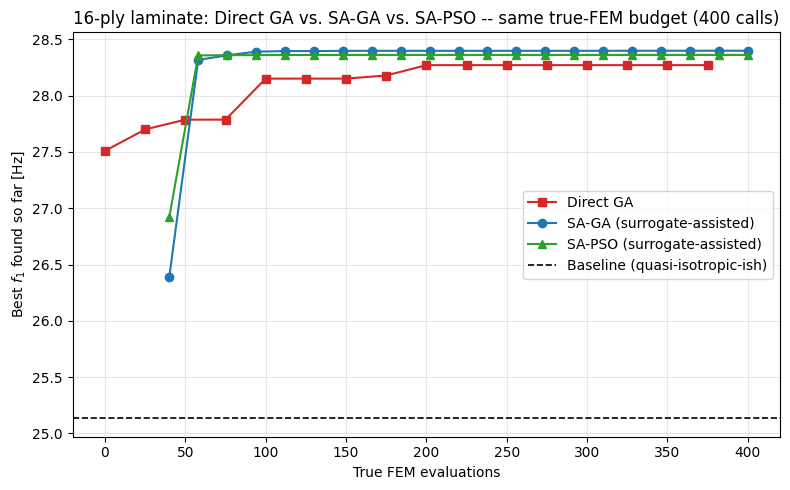

In [ ]:
import matplotlib.pyplot as plt

COLORS = {'Direct GA': '#d62728', 'SA-GA': '#1f77b4', 'SA-PSO': '#2ca02c'}

plt.figure(figsize=(8, 5))
plt.plot(np.arange(len(direct_hist))*25, direct_hist, 's-',
         color=COLORS['Direct GA'], label='Direct GA')
plt.plot(sa_ga_result['fem_calls'], sa_ga_result['best'], 'o-',
         color=COLORS['SA-GA'], label='SA-GA (surrogate-assisted)')
plt.plot(sa_pso_result['fem_calls'], sa_pso_result['best'], '^-',
         color=COLORS['SA-PSO'], label='SA-PSO (surrogate-assisted)')
plt.axhline(f_baseline, ls='--', c='k', lw=1.2, label='Baseline (quasi-isotropic-ish)')
plt.xlabel('True FEM evaluations')
plt.ylabel('Best $f_1$ found so far [Hz]')
plt.title(f'{2*n_half}-ply laminate: Direct GA vs. SA-GA vs. SA-PSO -- same true-FEM budget (400 calls)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()